# 04 · Ranking + SHAP

Puts the pieces together for one farm, using `project/recommend.py` (the same code the app and agent will call):

1. District → coordinates → NASA POWER weather (10-year mean temperature, mean monthly rainfall).
2. Crop model (Random Forest without humidity, trained with weather noise, isotonic-calibrated; notebook 05)
   → suitability per crop; keep the top 3 with suitability ≥ 5%.
3. Net return (Rs/ha) = district yield (t/ha) × 10 × forecast price at selling time (Rs/quintal) × (1 − cost share).
   Price: median of ETS, ARIMA, Theta and seasonal-naive (notebook 06). Selling time = sowing month + crop duration;
   perennials use the 12-month mean price. Cost share: CACP A2+FL ÷ gross value; crops CACP doesn't survey (fruit)
   get the median field-crop share, flagged as assumed.
4. **Order:** by suitability. Crops at least 80% as suitable as the top crop are near-ties and are ordered by net return
   (notebook 07: this kept the right crop first 98.5% of the time; suitability × revenue managed 94.5%).
5. SHAP: which inputs pushed each crop up or down.

**Example farms.** We have no real farm soil yet, so each farm gets the Kaggle mean soil of the crop its district is
known for. The soil then "fits" that crop, and the question is whether the district's **real** weather still lets the
model pick it. This previews the Nov 5–6 real-world check. Sowing date: Nov 3, 2026 (rabi).

In [1]:
import sys
sys.path.insert(0, '../project')
import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import shap

import data
import recommend

recommend.MODEL_FILE = 'kaggle_crop_model.joblib'  # this notebook tests the Kaggle model; the app uses the district model

RESULTS, FIGS = Path('../research/results'), Path('../research/figures')
SOW = datetime.date(2026, 11, 3)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 20)

In [2]:
crops = data.kaggle_crops()
soil = crops.groupby('label')[['N', 'P', 'K', 'ph']].mean().round(1)
farms = pd.DataFrame([
    ('Raipur', 'rice'), ('Yavatmal', 'cotton'), ('Vidisha', 'chickpea'), ('Nashik', 'grapes'), ('Ludhiana', 'maize'),
], columns=['district', 'known_for']).join(soil, on='known_for')
farms

,district,known_for,N,P,K,ph
0,Raipur,rice,79.9,47.6,39.9,6.4
1,Yavatmal,cotton,117.8,46.2,19.6,6.9
2,Vidisha,chickpea,40.1,67.8,79.9,7.3
3,Nashik,grapes,23.2,132.5,200.1,6.0
4,Ludhiana,maize,77.8,48.4,19.8,6.2


## 1. Ranked recommendations

In [3]:
tables, inputs = [], {}
for f in farms.itertuples():
    inp, t = recommend.recommend(f.N, f.P, f.K, f.ph, f.district, sow=SOW)
    inputs[f.district] = inp
    tables.append(t.assign(district=f.district, known_for=f.known_for, rank=t.index))
ranked = pd.concat(tables, ignore_index=True)
ranked.to_csv(RESULTS / '2026-11-03_ranking_examples.csv', index=False)

weather = pd.DataFrame(inputs).T[['state', 'temperature', 'humidity', 'rainfall']]
weather['kaggle rainfall of known crop'] = farms.set_index('district').known_for.map(crops.groupby('label').rainfall.mean()).round(1)
weather

,state,temperature,humidity,rainfall,kaggle rainfall of known crop
Raipur,Chhattisgarh,26.0,61.9,115.9,236.2
Yavatmal,Maharashtra,27.0,56.1,83.0,80.4
Vidisha,Madhya Pradesh,25.0,54.5,98.9,80.1
Nashik,Maharashtra,25.2,56.9,71.6,69.6
Ludhiana,Punjab,24.7,50.2,74.5,84.8


In [4]:
for d, t in ranked.groupby('district', sort=False):
    print(f"── {d} (known for {t.known_for.iloc[0]}) ──")
    print(t[['rank', 'crop', 'suitability', 'near_tie', 'yield_t_ha', 'yield_source', 'price_rs_q', 'price_source',
             'price_mape', 'revenue_rs_ha', 'cost_share', 'cost_source', 'net_rs_ha']].to_string(index=False), end='\n\n')

── Raipur (known for rice) ──
 rank crop  suitability  near_tie  yield_t_ha yield_source  price_rs_q price_source  price_mape  revenue_rs_ha  cost_share       cost_source  net_rs_ha
    1 jute        0.919      True        1.44 India median     11931.0    All India        21.1       171806.0        0.55    CACP All India    76624.0
    2 rice        0.081     False        2.92     district      1924.0 Chhattisgarh         5.7        56204.0        0.50 CACP Chhattisgarh    28269.0

── Yavatmal (known for cotton) ──
 rank   crop  suitability  near_tie  yield_t_ha yield_source  price_rs_q price_source  price_mape  revenue_rs_ha  cost_share      cost_source  net_rs_ha
    1 cotton          1.0      True        0.74     district      8498.0  Maharashtra         5.8        62505.0        0.88 CACP Maharashtra     7335.0

── Vidisha (known for chickpea) ──
 rank     crop  suitability  near_tie  yield_t_ha yield_source  price_rs_q   price_source  price_mape  revenue_rs_ha  cost_share         

In [5]:
hit = ranked.groupby('district', sort=False).apply(lambda t: pd.Series({
    'known crop in top 3': t.known_for.iloc[0] in set(t.crop),
    'known crop ranked 1st': t.crop.iloc[0] == t.known_for.iloc[0],
    'model top pick (suitability)': t.sort_values('suitability').crop.iloc[-1],
    'ranked 1st': t.crop.iloc[0],
}), include_groups=False)
hit

,known crop in top 3,known crop ranked 1st,model top pick (suitability),ranked 1st
district,,,,
Raipur,True,False,jute,jute
Yavatmal,True,True,cotton,cotton
Vidisha,True,True,chickpea,chickpea
Nashik,True,True,grapes,grapes
Ludhiana,True,True,maize,maize


## 2. Why? SHAP for each farm's top crop

Each bar is one input's push on that crop, starting from the average over all training rows (E[f(x)]) and ending at
this farm's score (f(x)). Red pushes up, blue pushes down. SHAP needs the forest itself, so f(x) is the forest's score
**before** calibration; the suitability in the table is that score after isotonic calibration, so the numbers differ
but the pushes point the same way.

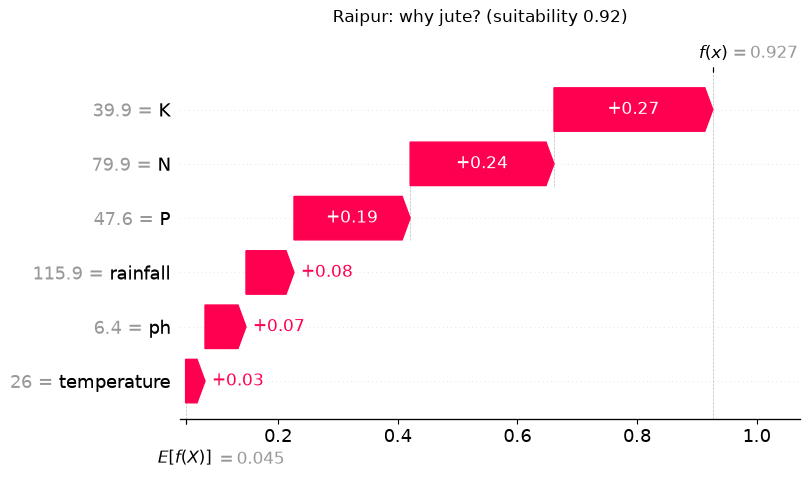

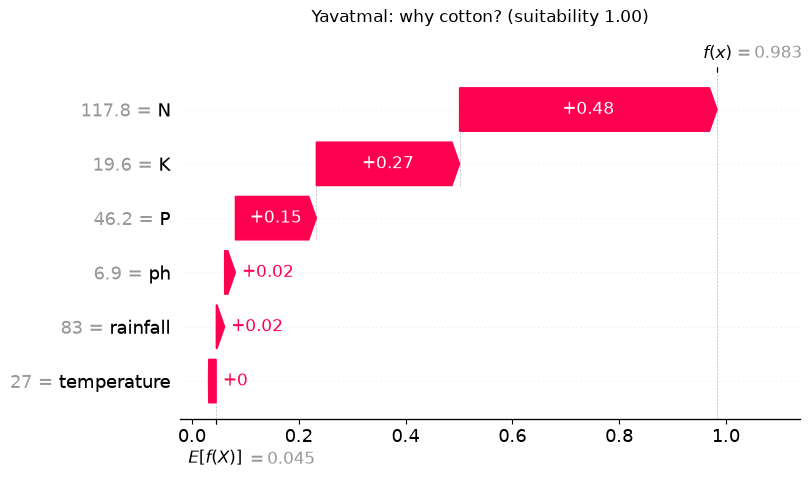

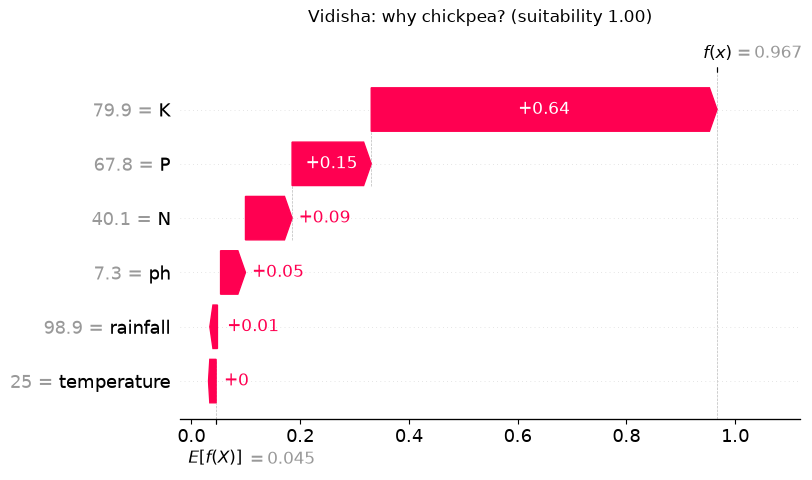

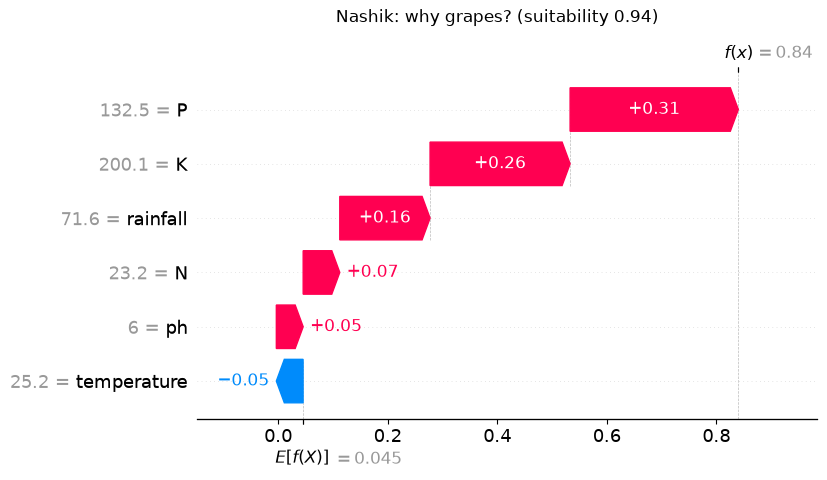

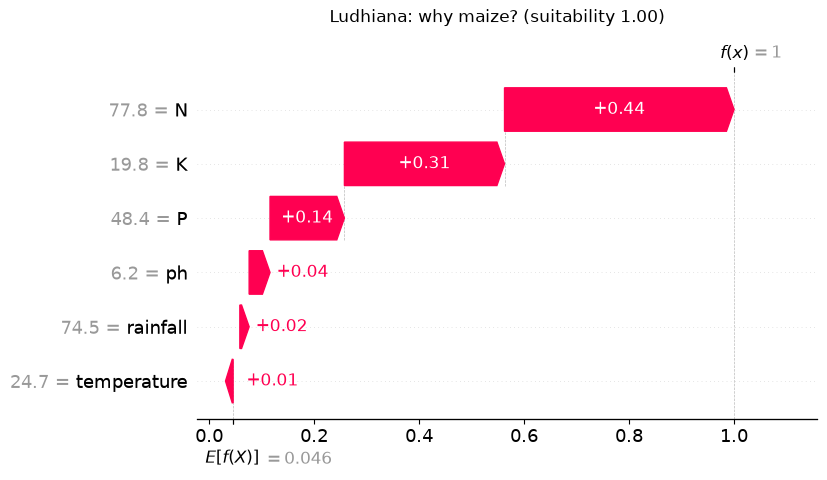

In [6]:
for d, t in ranked.groupby('district', sort=False):
    crop = t.crop.iloc[0]
    shap.plots.waterfall(recommend.explain(inputs[d], crop), show=False)
    fig = plt.gcf()
    fig.suptitle(f'{d}: why {crop}? (suitability {t.suitability.iloc[0]:.2f})', y=1.02)
    fig.savefig(FIGS / f'shap_{d.lower()}_{crop}.png', dpi=130, bbox_inches='tight')
    plt.show()

And for the known crop where the model didn't put it first: what held it back?

In [7]:
for f in farms.itertuples():
    t = ranked[ranked.district == f.district]
    if t.crop.iloc[0] == f.known_for:
        continue
    e = recommend.explain(inputs[f.district], f.known_for)
    print(f"{f.district}, {f.known_for}: forest score {e.base_values + e.values.sum():.3f}. Pushes:",
          pd.Series(e.values, index=e.feature_names).round(3).sort_values().to_dict())

Raipur, rice: forest score 0.070. Pushes: {'ph': -0.067, 'rainfall': -0.047, 'temperature': -0.025, 'P': 0.032, 'N': 0.053, 'K': 0.078}


## Findings (Nov 3, after applying the notebook 05–07 results)

- **The known crop is in the top 3 for all 5 farms** (old model: 4; Raipur rice had 0%), and **ranked first in 4 of 5**
  (old revenue ranking: 3, because papaya topped Raipur and Vidisha).
- **No fruit jumps a better-suited crop any more.** Near-ties are rare here: the calibrated model gives one crop ≥ 0.9
  in every farm, so net return didn't re-order anything in these 5 cases.
- **Raipur is still wrong: jute 0.92, rice 0.08.** Rice ↔ jute is the model's main confusion (notebook 02), and Raipur's
  real rainfall (116 mm/month) is half Kaggle's rice average (236). Training with weather noise lifted rice from 0 to 0.08,
  not to first. SHAP for rice: pH and rainfall push it down. Irrigation is still not an input.
- **Costs are big.** CACP A2+FL takes 88% of cotton's gross value in Maharashtra and 91% of maize's in Punjab, so their
  net return is only ~Rs 7,000/ha. These are 2017-22 survey medians applied to 2026-27 prices.
- Grapes' net return uses an assumed cost share (no CACP data for fruit) and is flagged in the table; apple has no yield.
- Small example (5 farms, Kaggle soil, one sowing date). Not a result for the paper, just a check that the pieces fit.